In [1]:
! pip3 install --user "pymongo"

In [2]:
import pymongo as pm
from pprint import pprint
import datetime
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
client = pm.MongoClient(
    'bigdatadb.polito.it',
    ssl=True,
    authSource='carsharing',
    username='ictts',
    password='Ict4SM22!',
    tlsAllowInvalidCertificates=True
)

In [4]:
db = client['carsharing']
pb_coll = db['PermanentBookings']
ab_coll = db['ActiveBookings']
pp_coll = db['PermanentParkings']
ap_coll = db['ActiveParkings']

In [5]:
#Step 1 : Preliminary data analysis

In [6]:
# How much data are present in each collection
# pb : 28 180 508
ab_coll.count_documents({})

8743

In [7]:
pp_coll.count_documents({})

28312676

In [8]:
# pp : 28312676
ap_coll.count_documents({})

4790

In [9]:
'''
Why the number of documents in PermanentParkings and PermanentBooking is similar?
'''
# at each booking you have a new parking slot at the end -> so add a period on both coll The slight differrence is due to caveats

'\nWhy the number of documents in PermanentParkings and PermanentBooking is similar?\n'

In [10]:
'''
For which cities the system is collecting data?
'''
# liste des actives plus courte
pb_coll.distinct("city")

['Amsterdam',
 'Austin',
 'Berlin',
 'Calgary',
 'Columbus',
 'Denver',
 'Firenze',
 'Frankfurt',
 'Hamburg',
 'Madrid',
 'Milano',
 'Montreal',
 'Munchen',
 'New York City',
 'Portland',
 'Rheinland',
 'Roma',
 'San Diego',
 'Seattle',
 'Stuttgart',
 'Torino',
 'Toronto',
 'Twin Cities',
 'Vancouver',
 'Washington DC',
 'Wien']

In [11]:
ab_coll.distinct("city")

['Amsterdam',
 'Austin',
 'Berlin',
 'Calgary',
 'Columbus',
 'Denver',
 'Firenze',
 'Frankfurt',
 'Hamburg',
 'Madrid',
 'Milano',
 'Montreal',
 'Munchen',
 'New York City',
 'Portland',
 'Rheinland',
 'Roma',
 'Seattle',
 'Stuttgart',
 'Torino',
 'Toronto',
 'Vancouver',
 'Washington DC',
 'Wien']

In [12]:
'''
When did each collection start? When did each collection end?
'''
res = pb_coll.find({},{'init_time':1,'_id':0}).sort("init_time", 1).limit(1)

In [13]:
list(res)
#2016-12-13 (unix traduction) et pour ab 2018-01-24

[{'init_time': 1481650703}]

In [14]:
res1 = pb_coll.find({},{'final_time':1,'_id':0}).sort("init_time", -1).limit(1)

In [15]:
list(res1)
#2018-01-31 et pour ab -1 (tjrs en cours)

[{'final_time': 1517404383}]

In [16]:
res2 = pp_coll.find({},{'init_time':1,'_id':0}).sort("init_time", 1).limit(1)

In [17]:
list(res2)
# same

[{'init_time': 1481650658}]

In [18]:
res3 = pp_coll.find({},{'final_time':1,'_id':0}).sort("init_time", -1).limit(1)

In [19]:
list(res3)
# same

[{'final_time': 1517404383}]

In [20]:
'''
What about the time zone of the init_date and init_time timestamps? Which time zone do they refer to?
'''
# UNIX = UTC+0 
# Offset : Torino : +1 : UNIX + 1*3600
# Offset : Columbus : -5 : UNIX - 5*3600
# Offset : Frankfurt : +1UNIX + 1*3600

'\nWhat about the time zone of the init_date and init_time timestamps? Which time zone do they refer to?\n'

In [21]:
"""
What is the total number of cars seen in the whole period in each city? How can you estimate the
fleet size in a given period, e.g., one week? How does this relate to the total number of vehicles seen
in the whole collection?
"""
res4=pb_coll.distinct("plate", {"city": "Torino"})

In [22]:
print(len(res4))

609


In [23]:
res5=pb_coll.distinct("plate", {"city": "Frankfurt"})

In [24]:
print(len(res5))

304


In [25]:
res6=pb_coll.distinct("plate", {"city": "Columbus"})

In [26]:
print(len(res6))

215


In [27]:
Init_Time = res = pb_coll.find({},{'init_time':1,'_id':0}).sort("init_time", 1).limit(1)
Final_Time = pb_coll.find({},{'final_time':1,'_id':0}).sort("init_time", -1).limit(1)

Init_Time = next(Init_Time)['init_time']
Final_Time = next(Final_Time)['final_time']

print(Init_Time, Final_Time)

1481650703 1517404383


In [28]:
pipeline = [
    {
        "$match": {
            "city": "Torino",
            "init_time": {
                "$gte": Init_Time,
                "$lte": Final_Time
            }
        }
    },
    {
        "$group": {
            "_id": {
                "week": {
                    "$dateTrunc": {
                        "date": {
                            "$toDate": {
                                "$multiply": ["$init_time", 1000]
                            }
                        },
                        "unit": "week",
                        "startOfWeek": "monday"
                    }
                },
                "plate": "$plate"
            }
        }
    },
    {
        "$group": {
            "_id": "$_id.week",
            "nb_plates": {"$sum": 1}
        }
    },
    {
        "$sort": {
            "_id": 1
        }
    }
]

weekly = list(pb_coll.aggregate(pipeline))

KeyboardInterrupt: 

In [ ]:
df = pd.DataFrame(weekly)

df.rename(columns={
    "_id": "week",
    "nb_plates": "unique_plates"
}, inplace=True)

df

In [ ]:
import matplotlib.pyplot as plt

# Moyenne du nombre de voitures uniques par semaine
mean_cars = df["unique_plates"].mean()

print(f"Nombre moyen de voitures par semaine à Turin : {mean_cars:.2f}")

# Graphique
plt.figure(figsize=(12, 5))

plt.plot(
    df["week"],
    df["unique_plates"],
    marker="o",
    label="Voitures uniques / semaine"
)

plt.axhline(
    mean_cars,
    linestyle="--",
    label=f"Moyenne : {mean_cars:.1f}"
)

plt.xlabel("Semaine")
plt.ylabel("Nombre de voitures uniques")
plt.title("Nombre de voitures uniques par semaine")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

In [ ]:
# How many bookings have been recorded in December 2017 in each city?
# = ok if begin time is in december

# Offset : Torino : +1 : UNIX + 1*3600
# Offset : Columbus : -5 : UNIX - 5*3600
# Offset : Frankfurt : +1UNIX + 1*3600

pb_turino_dec = pb_coll.count_documents({
    'city': 'Torino',
    'init_date': {
        '$gte': datetime.datetime(2017, 12, 1, 1, 0, 0), #01/12/2017 à 1h00.00 pour le offset de torino
        '$lt': datetime.datetime(2018, 1, 1, 1, 0, 0)
    }
})
pb_turino_dec

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Nombre de réservations par mois pour Torino en 2017
resa_par_mois = []

for mois in range(1, 13):
    date_debut = datetime.datetime(2017, mois, 1, 1, 0, 0)

    if mois == 12:
        date_fin = datetime.datetime(2018, 1, 1, 1, 0, 0)
    else:
        date_fin = datetime.datetime(2017, mois + 1, 1, 1, 0, 0)

    nb_resa = pb_coll.count_documents({
        'city': 'Torino',
        'init_date': {
            '$gte': date_debut,
            '$lt': date_fin
        }
    })

    resa_par_mois.append(nb_resa)

# Affichage du graphique
mois_labels = [
    'Janvier', 'Février', 'Mars', 'Avril', 'Mai', 'Juin',
    'Juillet', 'Août', 'Septembre', 'Octobre', 'Novembre', 'Décembre'
]

plt.figure(figsize=(12, 6))
plt.bar(mois_labels, resa_par_mois, color='steelblue')

plt.title('Nombre de réservations par mois à Torino en 2017')
plt.xlabel('Mois')
plt.ylabel('Nombre de réservations')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
pb_frankfurt_dec = pb_coll.count_documents({
    'city': 'Frankfurt',
    'init_date': {
        '$gte': datetime.datetime(2017, 12, 1, 1, 0, 0), #01/12/2017 à 1h00.00 pour le offset de frankfurt
        '$lt': datetime.datetime(2018, 1, 1, 1, 0, 0)
    }
})
pb_frankfurt_dec

In [ ]:
pb_columbus_dec = pb_coll.count_documents({
    'city': 'Columbus',
    'init_date': {
        '$gte': datetime.datetime(2017, 11, 30, 19, 0, 0), #30/11/2017 à 19h00.00 pour le offset de columbus
        '$lt': datetime.datetime(2017, 12, 31, 19, 0, 0)
    }
})
pb_columbus_dec

In [ ]:
# How many bookings have the alternative transportation modes recorded in each city?

pb_altmode_torino = pb_coll.count_documents({
    'city': 'Torino',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1},
    'public_transport.distance': {'$ne': 0},
    'public_transport.arrival_date': {'$ne': -1},
    'public_transport.arrival_time': {'$ne': -1}
})
pb_altmode_torino

In [ ]:
pb_altmode_torino = pb_coll.count_documents({
    'city': 'Torino',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1},
    'public_transport.arrival_date': {'$ne': -1},
    'public_transport.arrival_time': {'$ne': -1}
})
pb_altmode_torino

In [ ]:
pb_altmode_torino = pb_coll.count_documents({
    'city': 'Torino',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1}
})
pb_altmode_torino

In [ ]:
pb_altmode_torino = pb_coll.count_documents({
    'city': 'Torino',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1},
    'public_transport.distance': {'$ne': 0}
})
pb_altmode_torino

In [ ]:
pb_altmode_frankfurt = pb_coll.count_documents({
    'city': 'Frankfurt',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1},
    'public_transport.distance': {'$ne': 0},
    'public_transport.arrival_date': {'$ne': -1},
    'public_transport.arrival_time': {'$ne': -1}
})
pb_altmode_frankfurt

In [ ]:
pb_altmode_columbus = pb_coll.count_documents({
    'city': 'Columbus',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1},
    'public_transport.distance': {'$ne': 0},
    'public_transport.arrival_date': {'$ne': -1},
    'public_transport.arrival_time': {'$ne': -1}
})
pb_altmode_columbus

In [ ]:
## Step 2 – Car sharing usage characterization
"""
Consider each city of your group, and the period of time of November 1st 2017 – January 31st 2018.
Consider the time series (city, timestamp, duration, locations). Process it to further analyse it by producing
the following plots and results.
"""

In [ ]:
"""pb_timeseries = pb_coll.aggregate([
    {
        '$project': {
            '_id': 0,
            'city': 1,
            'init_date': 1,
            'final_date': 1,
            'init_address': 1,
            'final_address': 1,
            'origin_destination': 1,
            'duration': {
                '$subtract': ['$final_time', '$init_time']
            }
        }
    }
])

pb_timeseries_df = pd.DataFrame(list(pb_timeseries))
pb_timeseries_df.head(10).plot(
    x='city',
    y='duration',
    kind='bar',
    figsize=(10, 5)
)

plt.show()""""

In [ ]:
# Q1 Adam

In [ ]:
# Q2: Consider the system utilization over time: 
# aggregate rentals per hour of the day, and then plot the number of booked/parked cars (or percentage of booked/parked cars) per hour versus time of day.
# Do you notice any outliers? Can you explain them?

# V1 : We count a rental on all the hour time slot it appears 
# V2 : We count a rental only on the hour it begins in 

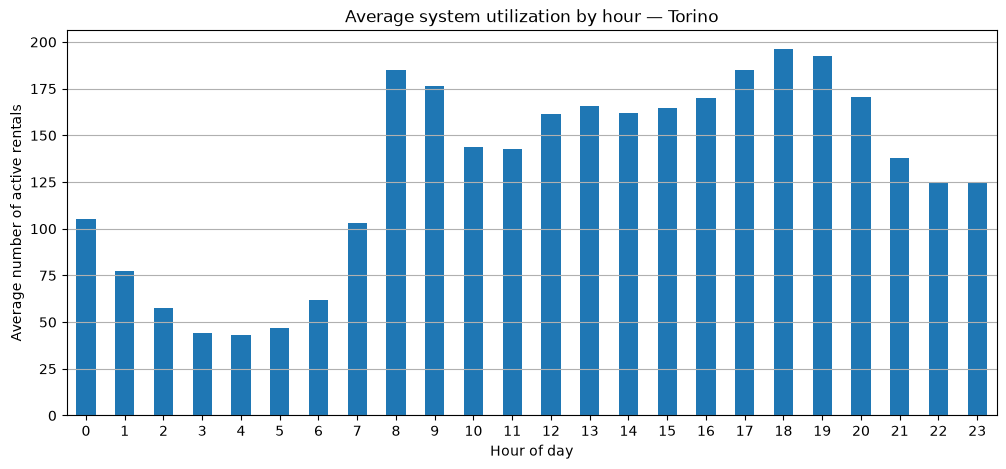

In [40]:
df = pd.DataFrame(list(pb_coll.find(
    {'city': 'Torino'},
    {
        '_id': 0,
        'init_date': 1,
        'final_date': 1
    }
)))

# Générer les heures de la série temporelle
hours = pd.date_range(
    df['init_date'].min().floor('h'),
    df['final_date'].max().floor('h'),
    freq='h'
)

# V1 : nombre de locations actives à chaque heure
hourly_rentals_v1 = pd.Series({
    hour: (
        (df['init_date'] < hour + pd.Timedelta(hours=1)) &
        (df['final_date'] > hour)
    ).sum()
    for hour in hours
})

# Regrouper par heure de la journée (0 à 23)
hourly_profile_v1 = hourly_rentals_v1.groupby(
    hourly_rentals_v1.index.hour
).mean().reindex(range(24), fill_value=0)

# Tracer le graphique
hourly_profile_v1.plot(
    kind='bar',
    figsize=(12, 5),
    rot=0
)

plt.xlabel('Hour of day')
plt.ylabel('Average number of permanent rentals')
plt.title('Average system utilization by hour — Torino')
plt.xticks(range(24))
plt.grid(axis='y')
plt.show()

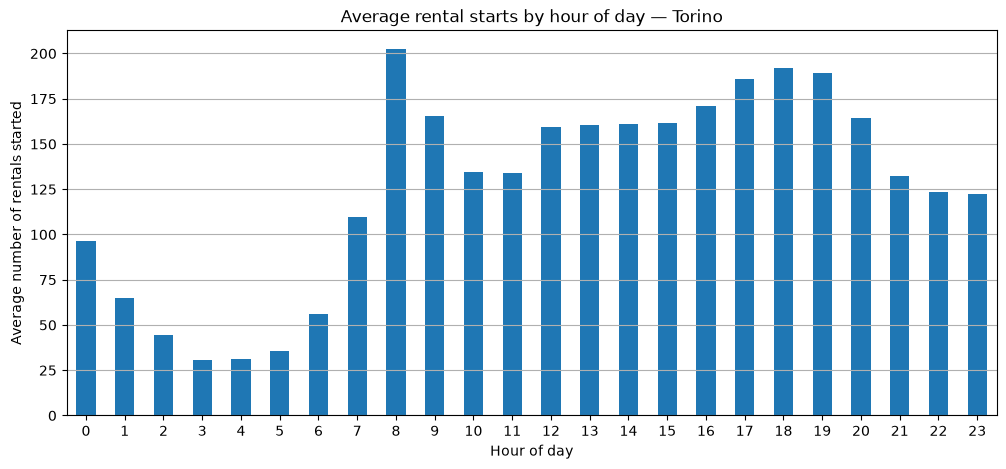

In [44]:
df = pd.DataFrame(list(pb_coll.find(
    {'city': 'Torino'},
    {
        '_id': 0,
        'init_date': 1
    }
)))

# Extraire le jour et l'heure de chaque location
df['day'] = df['init_date'].dt.date
df['hour'] = df['init_date'].dt.hour

# Compter les locations pour chaque jour et chaque heure
rentals_per_day_hour = (
    df.groupby(['day', 'hour'])
      .size()
      .rename('rentals')
      .reset_index()
)

# Calculer la moyenne par heure sur l'ensemble des jours
hourly_rentals_v2 = (
    rentals_per_day_hour.groupby('hour')['rentals']
    .mean()
    .reindex(range(24), fill_value=0)
)

# Tracer le graphique
hourly_rentals_v2.plot(
    kind='bar',
    figsize=(12, 5),
    rot=0
)

plt.xlabel('Hour of day')
plt.ylabel('Average number of rentals started')
plt.title('Average rental starts by hour of day — Torino')
plt.xticks(range(24))
plt.grid(axis='y')
plt.show()

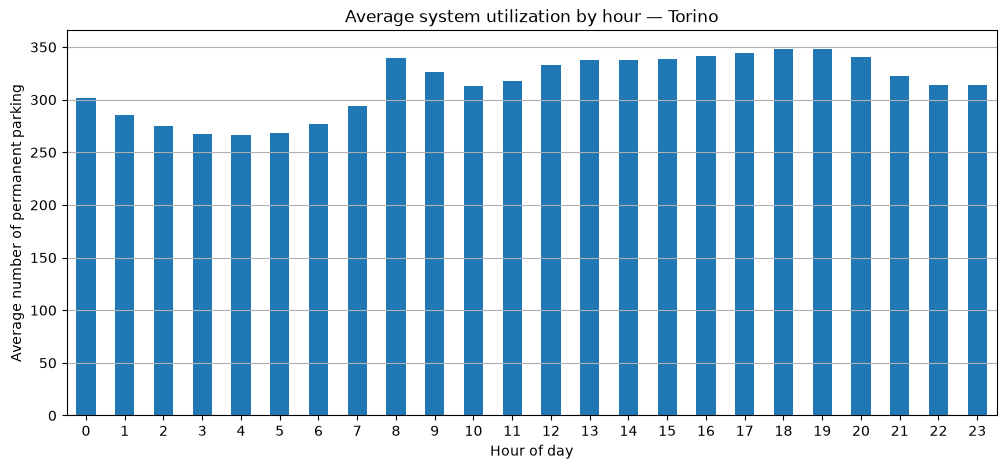

In [45]:
df = pd.DataFrame(list(pp_coll.find(
    {'city': 'Torino'},
    {
        '_id': 0,
        'init_date': 1,
        'final_date': 1
    }
)))

# Générer les heures de la série temporelle
hours = pd.date_range(
    df['init_date'].min().floor('h'),
    df['final_date'].max().floor('h'),
    freq='h'
)

# V1 : nombre de locations actives à chaque heure
hourly_rentals_v1 = pd.Series({
    hour: (
        (df['init_date'] < hour + pd.Timedelta(hours=1)) &
        (df['final_date'] > hour)
    ).sum()
    for hour in hours
})

# Regrouper par heure de la journée (0 à 23)
hourly_profile_v1 = hourly_rentals_v1.groupby(
    hourly_rentals_v1.index.hour
).mean().reindex(range(24), fill_value=0)

# Tracer le graphique
hourly_profile_v1.plot(
    kind='bar',
    figsize=(12, 5),
    rot=0
)

plt.xlabel('Hour of day')
plt.ylabel('Average number of permanent parking')
plt.title('Torino')
plt.xticks(range(24))
plt.grid(axis='y')
plt.show()

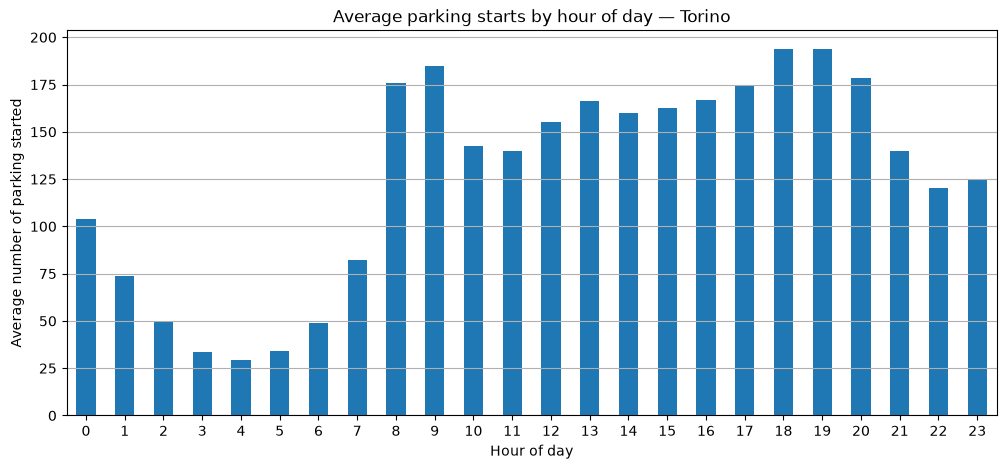

In [46]:
df = pd.DataFrame(list(pp_coll.find(
    {'city': 'Torino'},
    {
        '_id': 0,
        'init_date': 1
    }
)))

# Extraire le jour et l'heure de chaque location
df['day'] = df['init_date'].dt.date
df['hour'] = df['init_date'].dt.hour

# Compter les locations pour chaque jour et chaque heure
rentals_per_day_hour = (
    df.groupby(['day', 'hour'])
      .size()
      .rename('rentals')
      .reset_index()
)

# Calculer la moyenne par heure sur l'ensemble des jours
hourly_rentals_v2 = (
    rentals_per_day_hour.groupby('hour')['rentals']
    .mean()
    .reindex(range(24), fill_value=0)
)

# Tracer le graphique
hourly_rentals_v2.plot(
    kind='bar',
    figsize=(12, 5),
    rot=0
)

plt.xlabel('Hour of day')
plt.ylabel('Average number of parking started')
plt.title('Average parking starts by hour of day — Torino')
plt.xticks(range(24))
plt.grid(axis='y')
plt.show()

Nombre de locations valides : 873220
Nombre de voitures distinctes observées : 609
Valeurs manquantes : 0
Valeurs infinies : 0
0     17.24
1     12.75
2      9.40
3      7.28
4      7.04
5      7.71
6     10.16
7     16.90
8     30.34
9     28.98
10    23.61
11    23.39
12    26.47
13    27.17
14    26.59
15    27.02
16    27.95
17    30.39
18    32.24
19    31.61
20    28.03
21    22.63
22    20.50
23    20.55
dtype: float64


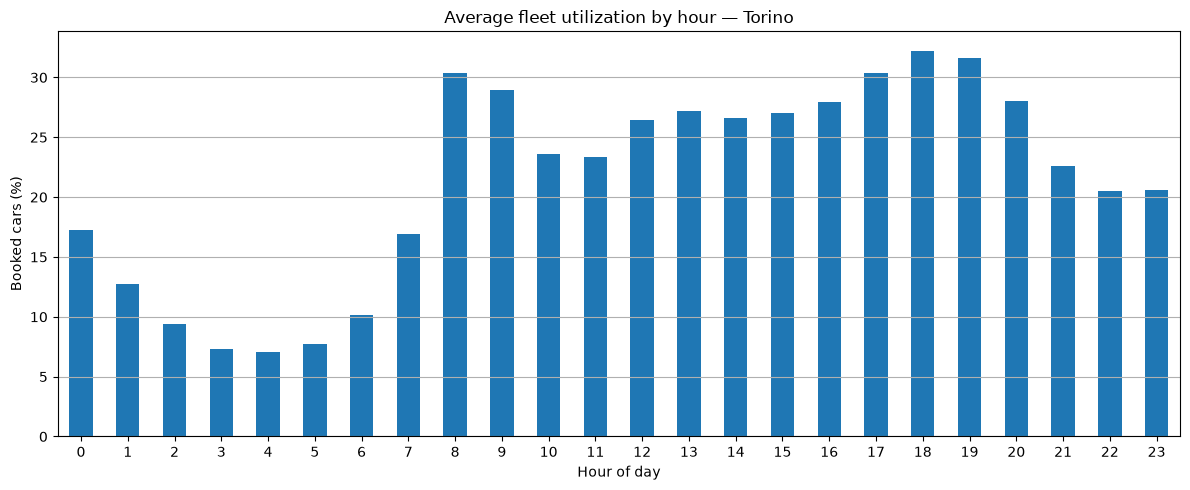

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Récupérer les locations de Torino
df = pd.DataFrame(list(pb_coll.find(
    {'city': 'Torino'},
    {
        '_id': 0,
        'init_date': 1,
        'final_date': 1,
        'plate': 1
    }
)))

# Convertir les dates
df['init_date'] = pd.to_datetime(df['init_date'])
df['final_date'] = pd.to_datetime(df['final_date'])

# Garder les locations valides
df = df.dropna(subset=['init_date', 'final_date'])
df = df[df['final_date'] > df['init_date']].copy()

if df.empty:
    raise ValueError("Aucune location valide trouvée pour Torino.")

# Nombre de voitures distinctes observées dans pb_coll
total_cars = df.loc[
    df['plate'].notna() & (df['plate'] != -1),
    'plate'
].nunique()

if total_cars == 0:
    raise ValueError("Aucune plaque valide trouvée dans les données.")

# Créer les créneaux horaires
hours = pd.date_range(
    df['init_date'].min().floor('h'),
    df['final_date'].max().ceil('h'),
    freq='h',
    inclusive='left'
)

# V1 : une location compte dans chaque heure qu'elle chevauche
hourly_rentals = pd.Series({
    hour: (
        (df['init_date'] < hour + pd.Timedelta(hours=1)) &
        (df['final_date'] > hour)
    ).sum()
    for hour in hours
})

# Moyenne par heure de la journée sur tous les jours observés
hourly_avg = (
    hourly_rentals.groupby(hourly_rentals.index.hour)
    .mean()
    .reindex(range(24), fill_value=0)
)

# Pourcentage approximatif de voitures occupées
utilization_pct = hourly_avg / total_cars * 100

print("Nombre de locations valides :", len(df))
print("Nombre de voitures distinctes observées :", total_cars)
print("Valeurs manquantes :", utilization_pct.isna().sum())
print("Valeurs infinies :", np.isinf(utilization_pct).sum())
print(utilization_pct.round(2))

# Tracer
utilization_pct.plot(
    kind='bar',
    figsize=(12, 5),
    rot=0
)

plt.xlabel('Hour of day')
plt.ylabel('Booked cars (%)')
plt.title('Average fleet utilization by hour — Torino')
plt.xticks(range(24))
plt.grid(axis='y')
plt.tight_layout()
plt.show()


In [ ]:
"""
Des pics le matin et en fin d'après-midi peuvent correspondre aux déplacements domicile-travail.
Un taux d'utilisation très élevé peut indiquer une forte demande.
Des pics isolés peuvent être dus à des événements particuliers ou à des anomalies dans les données.
"""